# Data Quality, Validation and Reconciliation

Analysis is only as trustworthy as the data under it. This notebook shows the controls that run
**before** any metric is computed:

1. Validation rules that stop the pipeline instead of producing quietly wrong numbers
2. Cleaning decisions, and how each one is counted rather than hidden
3. The ID-reconciliation method used to compare datasets without exposing identifiers
4. A cross-check: the same metrics computed twice (pandas and SQL) must agree
5. Proof that the Power BI export contains no identifiers

Runs on **synthetic data**, so every output is safe to publish.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.analysis.analyze_onboarding_funnel import OPTIONAL_COLUMNS, load_onboarding_data
from src.analysis.onboarding_behaviour import (
    MAX_PLAUSIBLE_SECONDS,
    build_cleaning_log,
    enrich_onboarding_data,
    parse_numeric,
)
from src.analysis.reconcile_datasets import calculate_overlaps
from src.config import SQL_DIR, SYNTHETIC_ONBOARDING_FILE
from src.data_generation.generate_synthetic_data import (
    generate_onboarding_data,
    main as generate_synthetic,
)
from src.database.run_sql_analysis import run_sql_analysis
from src.export.export_powerbi_data import export_powerbi_data
from src.visualization.make_charts import ACCENT, apply_style

# make_charts selects a headless backend for CI; switch back to inline display here.
%matplotlib inline

apply_style()
pd.options.display.float_format = "{:,.2f}".format

if not SYNTHETIC_ONBOARDING_FILE.exists():
    generate_synthetic(rows=25_000, seed=42)

tmp = Path(tempfile.mkdtemp())

## 1. Validation rules: breaking the data on purpose

Each case below corrupts a clean synthetic file in one specific way. The loader must reject it
with a clear message.

In [2]:
clean = generate_onboarding_data(rows=200, seed=1)

def corrupt(name, mutate):
    data = clean.copy()
    mutate(data)
    path = tmp / f"{name}.csv"
    data.to_csv(path, index=False)
    try:
        load_onboarding_data(path=path, verbose=False)
        return "ACCEPTED (unexpected!)"
    except ValueError as error:
        return f"rejected: {error}"

def duplicate_id(d):
    d.loc[1, "transaction_id"] = d.loc[0, "transaction_id"]

def missing_id(d):
    d.loc[0, "transaction_id"] = None

def missing_status(d):
    d.loc[0, "status"] = None

def unknown_status(d):
    d.loc[0, "status"] = "approved_maybe"

def drop_column(d):
    d.pop("source")

cases = {
    "Duplicate transaction ID": duplicate_id,
    "Missing transaction ID": missing_id,
    "Missing status": missing_status,
    "Unexpected status value": unknown_status,
    "Required column absent": drop_column,
}

pd.DataFrame(
    [(name, corrupt(f"case{i}", fn)) for i, (name, fn) in enumerate(cases.items())],
    columns=["Corruption", "Loader response"],
)

,Corruption,Loader response
0,Duplicate transaction ID,"rejected: Expected one record per transaction,..."
1,Missing transaction ID,rejected: Transaction IDs contain missing values.
2,Missing status,rejected: Status or source contains missing va...
3,Unexpected status value,rejected: Unexpected transaction statuses: {'a...
4,Required column absent,rejected: Missing required columns: ['source']


In [3]:
clean_path = tmp / "clean.csv"
clean.to_csv(clean_path, index=False)
ok = load_onboarding_data(path=clean_path, verbose=False)
print(f"Uncorrupted file loads normally: {len(ok):,} rows, all transaction IDs unique.")

Uncorrupted file loads normally: 200 rows, all transaction IDs unique.


**Why fail loudly?** A duplicate ID silently inflates every count; a missing status silently drops
rows from every group; an unexpected status means the KPI definitions no longer cover the data.
Stopping is safer than producing a plausible-looking but wrong report.

## 2. Cleaning decisions are counted, never hidden

The enrichment step parses timestamps, converts numbers and flags implausible durations. Every
action is tallied so it can be reviewed.

In [4]:
raw = load_onboarding_data(path=SYNTHETIC_ONBOARDING_FILE,
                           extra_columns=OPTIONAL_COLUMNS, verbose=False)
df = enrich_onboarding_data(raw)

build_cleaning_log(df)

,check,records,description
0,rows_processed,25000,Rows in the validated extract
1,unparsed_created_at,0,Timestamps that could not be parsed
2,time_spent_outliers_excluded,23,Journeys longer than 60 minutes excluded from ...
3,time_spent_missing,7917,Records without a recorded duration
4,update_counts_with_separator,1,Update counts stored with a thousands separator


### Numbers stored as text

Some exports format numbers with thousands separators (`"1,599"`). Parsed naively this becomes
missing data; the cleaner strips separators first.

In [5]:
examples = pd.Series(["75,206", "1,599", "12", "n/a", None])
pd.DataFrame({"raw text": examples, "parsed number": parse_numeric(examples)})

,raw text,parsed number
0,"75,206",75206
1,"1,599",1599
2,12,12
3,n/a,<NA>
4,NaN,<NA>


### Implausible journey durations

Durations are assumed to be in milliseconds. A handful of journeys last hours or days, which is
almost certainly a session artefact (for example a browser tab left open). They are **excluded from
timing statistics only**; the transaction still counts in outcome totals.

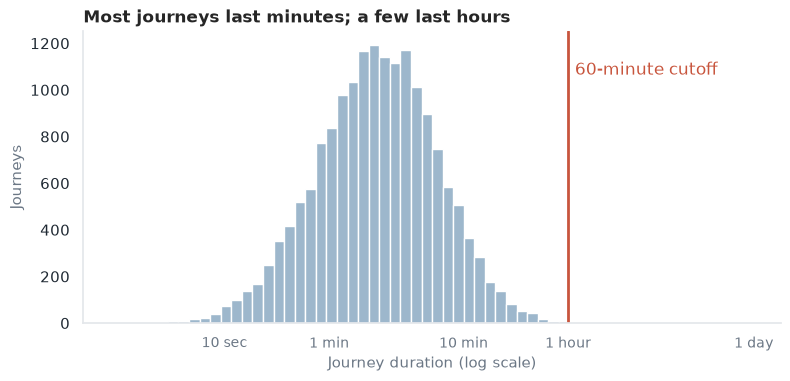

23 of 17,083 timed journeys (0.13%) excluded from timing statistics.


In [6]:
seconds = parse_numeric(raw["time_spent"]) / 1000
seconds = seconds.dropna()
cutoff = MAX_PLAUSIBLE_SECONDS

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(np.log10(seconds.clip(lower=1)), bins=60, color="#9DB7CC")
ax.axvline(np.log10(cutoff), color="#C8553D", linewidth=2)
ax.text(np.log10(cutoff) + 0.05, ax.get_ylim()[1] * 0.85,
        f"{cutoff // 60}-minute cutoff", color="#C8553D")
ticks = [10, 60, 600, 3600, 86400]
ax.set_xticks(np.log10(ticks))
ax.set_xticklabels(["10 sec", "1 min", "10 min", "1 hour", "1 day"])
ax.set_xlabel("Journey duration (log scale)")
ax.set_ylabel("Journeys")
ax.set_title("Most journeys last minutes; a few last hours", loc="left", fontweight="bold")
sns.despine()
plt.show()

excluded = int((seconds > cutoff).sum())
print(f"{excluded:,} of {len(seconds):,} timed journeys ({excluded / len(seconds) * 100:.2f}%) excluded from timing statistics.")

## 3. Reconciling datasets without exposing identifiers

Before joining extracts, it is important to know how they relate. The reconciliation compares sets
of transaction IDs and reports **only counts and percentages**.

| Measure | Meaning |
|---|---|
| Overlap count | IDs present in both datasets |
| Overlap % of A | Share of A's unique IDs that also appear in B |
| Jaccard similarity | Shared IDs / all distinct IDs across both |

Worked example: A has 100 unique IDs, B has 80, and 60 are shared.

In [7]:
ids_a = {f"a{i}" for i in range(40)} | {f"shared{i}" for i in range(60)}
ids_b = {f"b{i}" for i in range(20)} | {f"shared{i}" for i in range(60)}

result = calculate_overlaps({"Dataset A": ids_a, "Dataset B": ids_b})[0]

pd.Series({
    "unique IDs in A": result["unique_ids_a"],
    "unique IDs in B": result["unique_ids_b"],
    "shared IDs": result["overlapping_transaction_ids"],
    "% of A found in B": result["overlap_pct_of_a"],
    "% of B found in A": result["overlap_pct_of_b"],
    "Jaccard similarity %": result["jaccard_similarity_pct"],
}, name="value").to_frame()

,value
unique IDs in A,100.00
unique IDs in B,80.00
shared IDs,60.00
% of A found in B,60.00
% of B found in A,75.00
Jaccard similarity %,50.00


The measure is directional: 60% of A is found in B, but 75% of B is found in A. Jaccard collapses
both into one symmetric score (60 / 120 = 50%).

**Caveat.** A matching ID proves an *identifier* overlap, not a business relationship. Date ranges,
definitions and workflows must still be checked before datasets are combined. On the real data this
method revealed one extract that is a 100% duplicate of another's IDs, and another probably truncated
at Excel's row limit.

## 4. Two implementations must agree

Every headline metric is computed in **pandas** and in **SQL**. The pipeline asserts the results are
identical; a mismatch would mean a bug in one of them.

In [8]:
results = run_sql_analysis(df, tmp / "sql_out", tmp / "check.db", verify=True)

  ran sql/analysis/01_outcome_summary.sql -> 8 rows
  ran sql/analysis/02_headline_kpis.sql -> 1 rows
  ran sql/analysis/03_platform_cancellation.sql -> 6 rows
  ran sql/analysis/04_stage_dropoff.sql -> 5 rows
  ran sql/analysis/05_daily_trend.sql -> 31 rows
  ran sql/analysis/06_manual_review_workload.sql -> 2 rows
  [verified] Outcome counts match
  [verified] Headline KPI counts match
  [verified] Platform cancellation counts and rates match
  [verified] Stage drop-off counts match


In [9]:
print((SQL_DIR / "analysis" / "03_platform_cancellation.sql").read_text())
results["03_platform_cancellation"]

-- Q3. Cancellation rate by platform.
-- Restricted to 'finishTransaction' records: 'started' and agent-updated
-- records do not describe a user ending their journey.
SELECT
    platform,
    COUNT(*)                                                          AS finished_transactions,
    SUM(CASE WHEN status = 'user_cancelled' THEN 1 ELSE 0 END)        AS cancelled,
    ROUND(100.0 * SUM(CASE WHEN status = 'user_cancelled' THEN 1 ELSE 0 END) / COUNT(*), 2)
                                                                      AS cancellation_rate
FROM vw_onboarding_outcomes
WHERE source = 'finishTransaction'
GROUP BY platform
ORDER BY finished_transactions DESC, platform;



,platform,finished_transactions,cancelled,cancellation_rate
0,android,13644,3773,27.65
1,ios,2057,212,10.31
2,windows,876,246,28.08
3,missing,333,64,19.22
4,macos,122,22,18.03
5,unknown,51,10,19.61


## 5. The Power BI export contains no identifiers

The dashboard data is an **aggregated cube** (counts by date, hour, platform, status, stage and so
on) rather than row-level data. The export step asserts that its totals equal the source and that no
identifier column exists.

In [10]:
tables = export_powerbi_data(df, tmp / "powerbi")

fact = tables["fact_onboarding"]
print(f"\nSource rows:       {len(df):,}")
print(f"Cube rows:         {len(fact):,}  ({len(fact) / len(df) * 100:.0f}% of source)")
print(f"Total attempts:    {int(fact['transactions'].sum()):,}  (matches source)")
print(f"Identifier columns: {[c for c in fact.columns if 'id' in c.lower().split('_')] or 'none'}")
fact.head(3)

  wrote fact_onboarding.csv (13,627 rows)
  wrote dim_date.csv (31 rows)
  wrote dim_status.csv (8 rows)
  wrote dim_platform.csv (7 rows)
  wrote dim_stage.csv (9 rows)
  [verified] cube totals equal source totals; no identifiers

Source rows:       25,000
Cube rows:         13,627  (55% of source)
Total attempts:    25,000  (matches source)
Identifier columns: none


,created_date,created_hour,platform,status,source,stage,sdk_version,duration_band,transactions,time_spent_sum_seconds,time_spent_count
0,2026-03-01,0,android,auto_approved,finishTransaction,Location check,Web SDK: 9.12.0 Mobile SDK: 2.3.4,1. under 30 sec,1,22.00,1
1,2026-03-01,0,android,auto_approved,finishTransaction,Location check,Web SDK: 9.12.0 Mobile SDK: 2.3.4,4. 2-5 min,7,"1,410.00",7
2,2026-03-01,0,android,auto_approved,finishTransaction,Location check,Web SDK: 9.12.0 Mobile SDK: 2.3.4,5. 5-10 min,2,"1,004.60",2


## Summary

| Control | What it prevents |
|---|---|
| Fail-fast validation | Silently inflated or dropped records |
| Counted cleaning decisions | Hidden, unreviewable data changes |
| ID-level reconciliation | Joining extracts that do not mean what they appear to |
| pandas / SQL cross-check | A bug in either implementation going unnoticed |
| Aggregate-only exports | Leaking identifiers into dashboards or the repository |